# Classification and the Sigmoid Function

Classification is supervised learning: a model learns from examples with known labels, then predicts labels for new examples. A task is **binary** when there are two classes (spam or not spam) and **multiclass** when there are three or more (positive, neutral, or negative sentiment).

Logistic regression is a useful, interpretable baseline that estimates a class probability rather than an unbounded numeric value. Other methods include k-nearest neighbors (votes from nearby examples), decision trees (yes/no rules), random forests (votes across many trees), support vector machines, and naive Bayes. This lesson focuses on binary logistic regression.

Classification examples include spam detection, sentiment analysis, medical diagnosis, credit-risk assessment, and image recognition.


## 1. Turn a linear score into a probability

For features $x$, logistic regression first computes a linear score $z = w^T x + b$. The sigmoid (logistic) function maps that score to the probability of the positive class, $P(y=1\mid x)$:

$$\sigma(z) = \frac{1}{1 + e^{-z}}$$

Large positive scores map close to 1, large negative scores map close to 0, and a score of 0 maps to 0.5. The curve is S-shaped; it does not mean the underlying relationship between a feature and probability is always linear.


Scores: [-6  0  6]
Positive-class probabilities: [0.00247262 0.5        0.99752738]


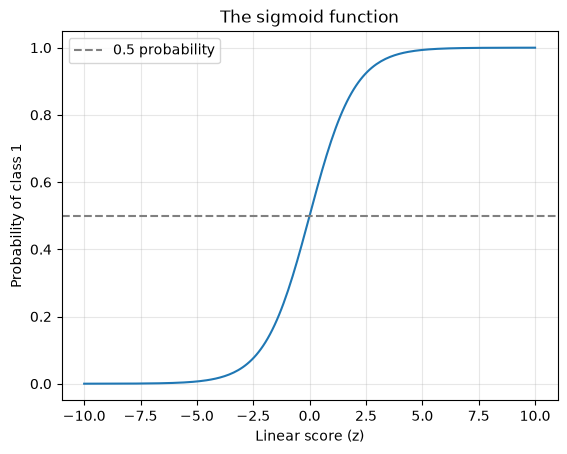

In [1]:
import numpy as np
import matplotlib.pyplot as plt


def sigmoid(z):
    return 1 / (1 + np.exp(-z))


scores = np.array([-6, 0, 6])
print("Scores:", scores)
print("Positive-class probabilities:", sigmoid(scores))

score_range = np.linspace(-10, 10, 200)
plt.plot(score_range, sigmoid(score_range))
plt.axhline(0.5, color="gray", linestyle="--", label="0.5 probability")
plt.xlabel("Linear score (z)")
plt.ylabel("Probability of class 1")
plt.title("The sigmoid function")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


## 2. A threshold turns probability into a class

The default decision threshold is 0.5: predict class 1 at or above the threshold, and class 0 below it. A threshold is a decision rule, not a change to the fitted probability model.

Choose a threshold based on the cost of mistakes. A higher threshold can reduce false alarms (for example, blocking real email); a lower threshold can reduce missed positive cases (for example, in an initial screening). Changing the threshold trades precision against recall, so evaluate the consequences on data that was not used to fit the model.


In [2]:
probabilities = np.array([0.18, 0.49, 0.73, 0.94])
threshold = 0.5
predicted_labels = (probabilities >= threshold).astype(int)

print("Probabilities:", probabilities)
print("Predicted labels:", predicted_labels)


Probabilities: [0.18 0.49 0.73 0.94]
Predicted labels: [0 0 1 1]


## Key ideas

- Logistic regression uses a linear score followed by a sigmoid to estimate a probability.
- The positive class is the class labeled `1`; the threshold converts its probability to a predicted label.
- Binary classification has two classes. Some classification problems are multiclass, but the worked examples here use binary labels.
